<a href="https://colab.research.google.com/github/ayush55223311/Ayush-Raj/blob/main/Data_Science_Internship_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install numpy pandas matplotlib seaborn scipy scikit-learn nltk

In [2]:
# Task 1.1: Descriptive Statistics

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

steps = np.array([
    6.5, 7.2, 8.1, 5.8, 9.0,
    7.5, 8.8, 6.2, 25.0, 7.8,
    6.9, 8.5, 7.1, 4.2, 30.5
])

print("Mean:", np.mean(steps))
print("Median:", np.median(steps))
print("Mode:", stats.mode(steps, keepdims=True).mode[0])
print("Variance:", np.var(steps))
print("Standard Deviation:", np.std(steps))

Q1 = np.percentile(steps, 25)
Q2 = np.percentile(steps, 50)
Q3 = np.percentile(steps, 75)
IQR = Q3 - Q1

print("Q1:", Q1)
print("Q2:", Q2)
print("Q3:", Q3)
print("IQR:", IQR)

Mean: 9.94
Median: 7.5
Mode: 4.2
Variance: 51.22773333333335
Standard Deviation: 7.157355191223456
Q1: 6.7
Q2: 7.5
Q3: 8.65
IQR: 1.9500000000000002


In [3]:
# Task 1.2: Standard Normal Distribution

from scipy import stats

mu = 170
sigma = 8

p_less_165 = stats.norm.cdf(165, mu, sigma)
p_more_180 = 1 - stats.norm.cdf(180, mu, sigma)
p_between = stats.norm.cdf(180, mu, sigma) - stats.norm.cdf(165, mu, sigma)
z_score = (185 - mu) / sigma

print("P(X < 165):", p_less_165)
print("P(X > 180):", p_more_180)
print("P(165 <= X <= 180):", p_between)
print("Z-score for 185 cm:", z_score)

P(X < 165): 0.26598552904870054
P(X > 180): 0.10564977366685535
P(165 <= X <= 180): 0.6283646972844441
Z-score for 185 cm: 1.875


In [4]:
# Task 1.3: One-Sample T-Test

from scipy import stats
import numpy as np

# H0: Average daily steps = 8 thousand
# H1: Average daily steps is not equal to 8 thousand

t_statistic, p_value = stats.ttest_1samp(steps, popmean=8)

print("Null Hypothesis (H0): Mean = 8")
print("Alternative Hypothesis (H1): Mean != 8")
print("T-statistic:", t_statistic)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Conclusion: Reject H0")
else:
    print("Conclusion: Fail to reject H0")

Null Hypothesis (H0): Mean = 8
Alternative Hypothesis (H1): Mean != 8
T-statistic: 1.014175646786735
P-value: 0.32770653158673113
Conclusion: Fail to reject H0


Q1: 6.7
Q3: 8.65
IQR: 1.9500000000000002
Lower Bound: 3.775
Upper Bound: 11.575000000000001
Outliers: [25.  30.5]
Mean before: 9.94
Mean after: 7.199999999999999


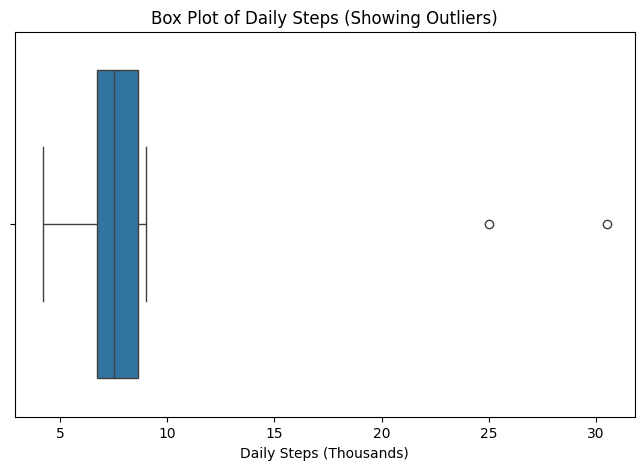

In [5]:
# Task 1.4: IQR Outlier Detection

Q1 = np.percentile(steps, 25)
Q3 = np.percentile(steps, 75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = steps[(steps < lower) | (steps > upper)]
clean = steps[(steps >= lower) & (steps <= upper)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Outliers:", outliers)
print("Mean before:", np.mean(steps))
print("Mean after:", np.mean(clean))

plt.figure(figsize=(8, 5))
sns.boxplot(x=steps)
plt.title("Box Plot of Daily Steps (Showing Outliers)")
plt.xlabel("Daily Steps (Thousands)")
plt.show()

**Impact of Outliers**

The original dataset contains two unusually high values, 25.0 and 30.5 thousand steps. These outliers increase the overall mean and make the data appear higher than the typical daily step count. After removing them using the IQR method, the mean decreases, providing a better representation of the usual daily activity in this dataset.

MSE: 45838362.12012498
RMSE: 6770.403394194838
R-squared: 0.18026902181505788


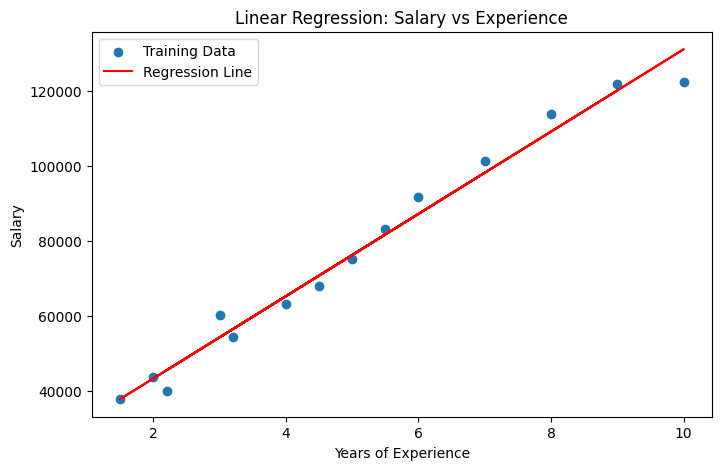

Predicted salary for 12 years: 152953.65626997023


In [6]:
# Task 2A: Linear Regression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

data = {
    "years_experience": [
        1.1, 1.3, 1.5, 2.0, 2.2, 2.9,
        3.0, 3.2, 3.7, 4.0, 4.5, 5.0,
        5.5, 6.0, 7.0, 8.0, 9.0, 10.0
    ],
    "salary": [
        39343, 46205, 37731, 43525, 39891, 56642,
        60150, 54445, 57189, 63218, 67938, 75000,
        83088, 91738, 101302, 113812, 121872, 122391
    ]
}

df_salary = pd.DataFrame(data)

X = df_salary[["years_experience"]]
y = df_salary["salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

# Regression line on training data
plt.figure(figsize=(8, 5))
plt.scatter(X_train["years_experience"], y_train, label="Training Data")
plt.plot(
    X_train["years_experience"],
    model.predict(X_train),
    color="red",
    label="Regression Line"
)

plt.title("Linear Regression: Salary vs Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

# Predict salary for 12 years of experience
predicted_salary = model.predict(pd.DataFrame({
    "years_experience": [12]
}))

print("Predicted salary for 12 years:", predicted_salary[0])

In [7]:
# Task 2B: Logistic Regression

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

Accuracy: 0.956140350877193
Confusion Matrix:
[[39  4]
 [ 1 70]]
Classification Report:
              precision    recall  f1-score   support

   malignant       0.97      0.91      0.94        43
      benign       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [8]:
# Task 3A: Compare Classification Models

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

knn = KNeighborsClassifier(n_neighbors=5)
dt = DecisionTreeClassifier(random_state=42)
nb = GaussianNB()

knn.fit(X_train, y_train)
dt.fit(X_train, y_train)
nb.fit(X_train, y_train)

knn_acc = accuracy_score(y_test, knn.predict(X_test))
dt_acc = accuracy_score(y_test, dt.predict(X_test))
nb_acc = accuracy_score(y_test, nb.predict(X_test))

print("KNN Accuracy:", knn_acc)
print("Decision Tree Accuracy:", dt_acc)
print("Naive Bayes Accuracy:", nb_acc)

KNN Accuracy: 1.0
Decision Tree Accuracy: 1.0
Naive Bayes Accuracy: 0.9777777777777777


In [9]:
# Task 3B: NLP Text Preprocessing

import re
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required NLTK resources
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

text = (
    "Data Science is an exciting field. It involves analyzing "
    "large datasets, building predictive models, and visualizing "
    "insights. Companies in 2025 are investing heavily in AI and ML!"
)

# Step 1: Lowercase
lower_text = text.lower()
print("Lowercase:", lower_text)

# Step 2: Remove punctuation and numbers
cleaned_text = re.sub(r"[^a-z\s]", "", lower_text)
print("\nCleaned:", cleaned_text)

# Step 3: Tokenization
tokens = word_tokenize(cleaned_text)
print("\nTokens:", tokens)

# Step 4: Remove stopwords
stop_words = set(stopwords.words("english"))
filtered = [word for word in tokens if word not in stop_words]
print("\nAfter stopword removal:", filtered)

# Step 5: Stemming
ps = PorterStemmer()
stemmed = [ps.stem(word) for word in filtered]
print("\nStemmed:", stemmed)

# Step 6: Lemmatization
lem = WordNetLemmatizer()
lemmatized = [lem.lemmatize(word) for word in filtered]
print("\nLemmatized:", lemmatized)

Lowercase: data science is an exciting field. it involves analyzing large datasets, building predictive models, and visualizing insights. companies in 2025 are investing heavily in ai and ml!

Cleaned: data science is an exciting field it involves analyzing large datasets building predictive models and visualizing insights companies in  are investing heavily in ai and ml

Tokens: ['data', 'science', 'is', 'an', 'exciting', 'field', 'it', 'involves', 'analyzing', 'large', 'datasets', 'building', 'predictive', 'models', 'and', 'visualizing', 'insights', 'companies', 'in', 'are', 'investing', 'heavily', 'in', 'ai', 'and', 'ml']

After stopword removal: ['data', 'science', 'exciting', 'field', 'involves', 'analyzing', 'large', 'datasets', 'building', 'predictive', 'models', 'visualizing', 'insights', 'companies', 'investing', 'heavily', 'ai', 'ml']

Stemmed: ['data', 'scienc', 'excit', 'field', 'involv', 'analyz', 'larg', 'dataset', 'build', 'predict', 'model', 'visual', 'insight', 'compan